# Neutron powder diffraction and Rietveld refinement

How much ferrite and how much austenite is there in a duplex stainless steel? This notebook simulates a neutron
powder diffraction measurement of a two-phase steel, refines it with the Rietveld method and turns every step
into a scene of a SciView film:

1. **The crystal structures**: ferrite (body-centred cubic) and austenite (face-centred cubic).
2. **The measurement**: the reflections allowed by each structure, their intensities and peak shapes, and the
   counts recorded by the detector bank.
3. **The Rietveld refinement**: the whole pattern fitted in four stages, from the starting model to the final fit.
4. **The result**: lattice parameters, phase fractions and agreement factors, with uncertainties.
5. **The film**: five scenes made from these results, rendered to MP4.

The pattern is simulated, so the refined numbers can be checked against the truth. The model is deliberately
small (cubic phases, isotropic Debye–Waller factors, no absorption or texture) so every line can be read;
for real data use a full Rietveld program (FullProf, GSAS-II, TOPAS) and make the film from its output files in
the same way as step 5.

Install: `pip install "sciview[math,science]"` (SciPy does the fitting).

In [1]:
import itertools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares

import sciview as sv
from sciview.jupyter import still

FILM = Path("films/diffraction")
ASSETS = FILM / "assets"
(ASSETS / "refinement").mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(11)
print("SciView", sv.__version__)

SciView 1.0.0


## 1. The crystal structures

Both phases are cubic iron alloys. In the body-centred cell (2 atoms) a reflection $hkl$ is allowed when
$h+k+l$ is even; in the face-centred cell (4 atoms) when $h, k, l$ are all even or all odd. The structure factor
of an allowed reflection is then $F = n\,b$, with $n$ the atoms per cell and $b$ the neutron scattering length.

In [2]:
LAMBDA = 1.155                      # Å, neutron wavelength from the monochromator
TTH = np.arange(5.0, 160.0001, 0.05)  # detector angles 2θ (degrees)

PHASES = {
    #             lattice  atoms/cell  b (fm, alloy average)  formula units  molar mass  colour in the film
    "ferrite":   dict(lattice="bcc", n=2, b=8.0, Z=2, M=55.5, color="ferrite"),
    "austenite": dict(lattice="fcc", n=4, b=8.5, Z=4, M=55.5, color="austenite"),
}


def allowed(h, k, l, lattice):
    if lattice == "bcc":
        return (h + k + l) % 2 == 0
    return len({h % 2, k % 2, l % 2}) == 1


def multiplicity(h, k, l):
    """How many equivalent planes {hkl} a cubic crystal has (permutations and signs)."""
    return len({tuple(s * v for s, v in zip(signs, perm))
                for perm in itertools.permutations((h, k, l))
                for signs in itertools.product((1, -1), repeat=3)})


def reflections(phase, a):
    """Allowed reflections inside the detector's range: (hkl, multiplicity, h²+k²+l²)."""
    out = []
    smax = (2 * a * np.sin(np.radians(TTH[-1] / 2)) / LAMBDA) ** 2
    for h in range(9):
        for k in range(h + 1):
            for l in range(k + 1):
                s2 = h * h + k * k + l * l
                if 0 < s2 <= smax and allowed(h, k, l, PHASES[phase]["lattice"]):
                    out.append(((h, k, l), multiplicity(h, k, l), s2))
    return sorted(out, key=lambda r: r[2])


HKL = {"ferrite": reflections("ferrite", 2.88), "austenite": reflections("austenite", 3.60)}
for phase, refl in HKL.items():
    print(f"{phase:10s} {len(refl)} reflections:", " ".join("".join(map(str, r[0])) for r in refl))

ferrite    13 reflections: 110 200 211 220 310 222 321 400 330 411 420 332 422
austenite  15 reflections: 111 200 220 311 222 400 331 420 422 333 511 440 531 442 600


## 2. The measurement

The calculated pattern is the background plus, for each phase $p$ and reflection, a peak at Bragg's angle
$\lambda = 2d\sin\theta$ with $d = a/\sqrt{h^2+k^2+l^2}$:

$$y_i = b_i + \sum_p S_p \sum_{hkl} m\, L(\theta)\, |F|^2\, e^{-2B\sin^2\theta/\lambda^2}\,
\Phi(2\theta_i - 2\theta_{hkl} - z)$$

with $S_p$ the scale factor, $m$ the multiplicity, $L = 1/(\sin^2\theta\cos\theta)$ the Lorentz factor, $B$ the
Debye–Waller factor, $z$ the detector's zero shift and $\Phi$ a pseudo-Voigt peak whose width follows the
Caglioti law $H^2 = U\tan^2\theta + V\tan\theta + W$. The background is a cubic Chebyshev polynomial.

3101 points from 5° to 160°, strongest peak 6208 counts


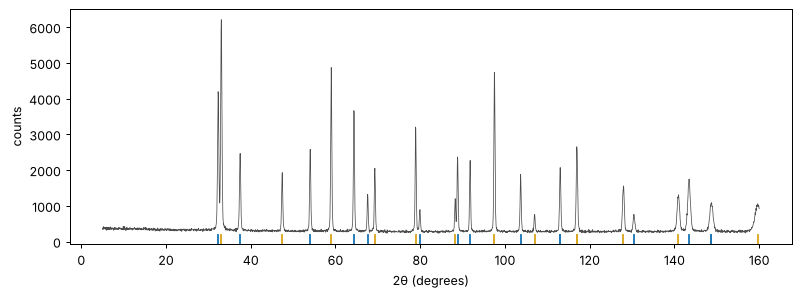

In [3]:
NAMES = ["zero", "b0", "b1", "b2", "b3", "S_ferrite", "S_austenite", "a_ferrite", "a_austenite",
         "U", "V", "W", "eta", "B_ferrite", "B_austenite"]
P = {name: i for i, name in enumerate(NAMES)}
X = (TTH - TTH.mean()) / (TTH[-1] - TTH.mean())       # 2θ mapped to [-1, 1] for the background


def pseudo_voigt(x, fwhm, eta):
    gauss = 2 / fwhm * np.sqrt(np.log(2) / np.pi) * np.exp(-4 * np.log(2) * x ** 2 / fwhm ** 2)
    lorentz = 2 / (np.pi * fwhm) / (1 + 4 * x ** 2 / fwhm ** 2)
    return eta * lorentz + (1 - eta) * gauss


def background(q):
    return q[P["b0"]] + q[P["b1"]] * X + q[P["b2"]] * (2 * X ** 2 - 1) + q[P["b3"]] * (4 * X ** 3 - 3 * X)


def peaks(q, phase):
    """Every reflection of one phase: 2θ (degrees, with the zero shift) and integrated intensity."""
    v = PHASES[phase]
    a, scale, B = q[P[f"a_{phase}"]], q[P[f"S_{phase}"]], q[P[f"B_{phase}"]]
    s2 = np.array([r[2] for r in HKL[phase]])
    m = np.array([r[1] for r in HKL[phase]])
    theta = np.arcsin(LAMBDA * np.sqrt(s2) / (2 * a))
    lorentz = 1 / (np.sin(theta) ** 2 * np.cos(theta))
    f2 = (v["n"] * v["b"]) ** 2 * np.exp(-2 * B * (np.sin(theta) / LAMBDA) ** 2)
    return np.degrees(2 * theta) + q[P["zero"]], scale * m * lorentz * f2, theta


def phase_pattern(q, phase):
    pos, area, theta = peaks(q, phase)
    U, V, W, eta = q[P["U"]], q[P["V"]], q[P["W"]], q[P["eta"]]
    fwhm = np.sqrt(np.maximum(U * np.tan(theta) ** 2 + V * np.tan(theta) + W, 1e-4))
    return (area[:, None] * pseudo_voigt(TTH[None, :] - pos[:, None], fwhm[:, None], eta)).sum(0)


def calculated(q):
    return background(q) + sum(phase_pattern(q, phase) for phase in PHASES)


def weight_fractions(q):
    """Hill & Howard: W_p ∝ S_p Z_p M_p V_p."""
    zmv = np.array([q[P[f"S_{p}"]] * v["Z"] * v["M"] * q[P[f"a_{p}"]] ** 3 for p, v in PHASES.items()])
    return zmv / zmv.sum()


# The truth: a duplex steel with 55 % ferrite, and an instrument with a small zero shift.
TRUE_W = np.array([0.55, 0.45])
truth = np.array([0.04, 300, -40, 25, -10, 0, 0, 2.8745, 3.5985, 0.10, -0.18, 0.16, 0.35, 0.35, 0.55])
scales = TRUE_W / np.array([v["Z"] * v["M"] * truth[P[f"a_{p}"]] ** 3 for p, v in PHASES.items()])
truth[[P["S_ferrite"], P["S_austenite"]]] = scales
truth[[P["S_ferrite"], P["S_austenite"]]] *= 6000 / (calculated(truth) - background(truth)).max()

observed = rng.poisson(calculated(truth)).astype(float)
weights = 1 / np.maximum(observed, 1)
print(f"{TTH.size} points from {TTH[0]:.0f}° to {TTH[-1]:.0f}°, strongest peak {observed.max():.0f} counts")

fig, ax = plt.subplots()
ax.plot(TTH, observed, color="0.3", lw=0.6)
for phase, color in (("ferrite", "goldenrod"), ("austenite", "tab:blue")):
    for x in peaks(truth, phase)[0]:
        ax.axvline(x, ymax=0.04, color=color)
ax.set_xlabel("2θ (degrees)")
ax.set_ylabel("counts")
fig.tight_layout()

## 3. The Rietveld refinement

The refinement minimises $\chi^2 = \sum_i w_i\,(y_i^{obs} - y_i^{calc})^2$ with $w_i = 1/y_i^{obs}$. It starts
from textbook lattice parameters and a rough instrument description, and frees the parameters in stages, as one
does by hand: a fit with everything free from a poor start can wander off.

The quality of the fit is the weighted profile R-factor $R_{wp} = \sqrt{\sum w (y^{obs}-y^{calc})^2 /
\sum w (y^{obs})^2}$, compared with the best possible value $R_{exp}$ given the counting statistics.

In [4]:
start = np.array([0.0, observed.min(), 0, 0, 0, 0, 0, 2.8665, 3.5900, 0.20, -0.20, 0.10, 0.50, 0.50, 0.50])
start[[P["S_ferrite"], P["S_austenite"]]] = truth[[P["S_ferrite"], P["S_austenite"]]] * 0.6
STAGES = [
    ("scale and background", ["b0", "b1", "b2", "b3", "S_ferrite", "S_austenite"]),
    ("lattice parameters and zero shift", ["zero", "a_ferrite", "a_austenite"]),
    ("peak shape", ["U", "V", "W", "eta"]),
    ("Debye–Waller factors", ["B_ferrite", "B_austenite"]),
]


def rwp(q):
    return np.sqrt(np.sum(weights * (observed - calculated(q)) ** 2) / np.sum(weights * observed ** 2))


q = start.copy()
free = []
history = [("starting model", q.copy())]
print(f"{'starting model':36s} Rwp {100 * rwp(q):5.1f} %")
for label, names in STAGES:
    free += [P[n] for n in names]

    def residuals(p, free=free):
        trial = q.copy()
        trial[free] = p
        return (observed - calculated(trial)) * np.sqrt(weights)

    result = least_squares(residuals, q[free], x_scale="jac")
    q[free] = result.x
    history.append((label, q.copy()))
    print(f"+ {label:34s} Rwp {100 * rwp(q):5.1f} %   ({len(free)} parameters)")

starting model                       Rwp  46.1 %
+ scale and background               Rwp  40.8 %   (6 parameters)
+ lattice parameters and zero shift  Rwp  14.6 %   (9 parameters)
+ peak shape                         Rwp   5.4 %   (13 parameters)
+ Debye–Waller factors               Rwp   4.8 %   (15 parameters)


## 4. The result

The uncertainties come from the covariance matrix of the last stage (all parameters free), scaled by the
reduced $\chi^2$. The weight fractions follow from the scale factors (Hill & Howard), with their uncertainties
propagated through the covariance.

ferrite    a = 2.87450(2) Å (true 2.8745)   54.8(2) wt% (true 55)
austenite  a = 3.59848(2) Å (true 3.5985)   45.2(2) wt% (true 45)
zero shift 0.0401(6)° (true 0.04)
Rwp 4.80 %, Rexp 4.79 %, chi² 1.00


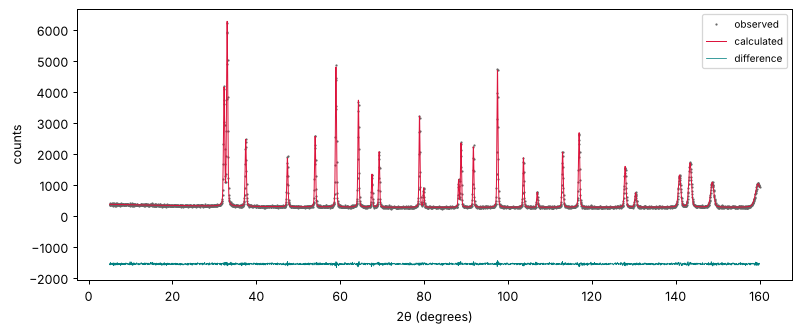

In [5]:
def paren(value, esd):
    """Crystallographers' notation: 2.87450(2) means 2.87450 ± 0.00002."""
    digits = max(0, -int(np.floor(np.log10(esd))))
    if round(esd * 10 ** digits) < 2:                   # an uncertainty starting with 1 keeps two digits
        digits += 1
    return f"{value:.{digits}f}({round(esd * 10 ** digits)})"


J = result.jac
chi2 = np.sum(result.fun ** 2) / (TTH.size - len(free))
cov = np.zeros((len(NAMES), len(NAMES)))
cov[np.ix_(free, free)] = np.linalg.inv(J.T @ J) * chi2
esd = np.sqrt(np.diag(cov))

fractions = weight_fractions(q)
grad = np.zeros((2, len(NAMES)))                          # numerical gradient of the fractions
for i in free:
    dq = np.zeros(len(NAMES))
    dq[i] = 1e-6 * max(abs(q[i]), 1e-3)
    grad[:, i] = (weight_fractions(q + dq) - weight_fractions(q - dq)) / (2 * dq[i])
fraction_esd = np.sqrt(np.diag(grad @ cov @ grad.T))
r_wp, r_exp = rwp(q), np.sqrt((TTH.size - len(free)) / np.sum(weights * observed ** 2))

for phase, w, dw in zip(PHASES, fractions, fraction_esd):
    i = P[f"a_{phase}"]
    print(f"{phase:10s} a = {paren(q[i], esd[i])} Å (true {truth[i]})   "
          f"{paren(100 * w, 100 * dw)} wt% (true {100 * TRUE_W[list(PHASES).index(phase)]:.0f})")
print(f"zero shift {paren(q[P['zero']], esd[P['zero']])}° (true {truth[P['zero']]})")
print(f"Rwp {100 * r_wp:.2f} %, Rexp {100 * r_exp:.2f} %, chi² {(r_wp / r_exp) ** 2:.2f}")

final = calculated(q)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(TTH, observed, ".", ms=1.5, color="0.4", label="observed")
ax.plot(TTH, final, color="crimson", lw=0.8, label="calculated")
ax.plot(TTH, observed - final - 0.25 * observed.max(), color="teal", lw=0.6, label="difference")
ax.set_xlabel("2θ (degrees)")
ax.set_ylabel("counts")
ax.legend(fontsize=8)
fig.tight_layout()

## 5. The film

The film reads CSV files from its `assets` folder. The refinement is a **file pattern**,
`assets/refinement/*.csv`, one file per frame; the calculated curve's `step` property walks through them, and
SciView interpolates between neighbouring files, so the curve moves smoothly. Between two stages the frames
interpolate the parameters, so the peaks slide into place rather than fade.

In [6]:
TOP = observed.max()
OFFSET = -0.30 * TOP                                   # where the difference curve sits under the pattern
np.savetxt(ASSETS / "pattern.csv", np.c_[TTH, observed, final, observed - final + OFFSET], delimiter=",",
           header="tth,observed,calculated,difference", comments="", fmt="%.3f")

FRAMES_PER_STAGE = 8
frames = [history[0][1]]
for (_, q0), (_, q1) in zip(history, history[1:]):
    frames += [q0 + (q1 - q0) * s for s in np.linspace(0, 1, FRAMES_PER_STAGE + 1)[1:]]
frame_rwp = []
for k, qk in enumerate(frames):
    yk = calculated(qk)
    frame_rwp.append(100 * rwp(qk))
    np.savetxt(ASSETS / "refinement" / f"frame_{k:03d}.csv", np.c_[TTH, yk, observed - yk + OFFSET],
               delimiter=",", header="tth,calculated,difference", comments="", fmt="%.3f")

ticks = {}
for row, phase in enumerate(PHASES):                   # one row of tick marks per phase under the pattern
    pos = peaks(q, phase)[0]
    y = -(0.07 + 0.07 * row) * TOP
    np.savetxt(ASSETS / f"ticks_{phase}.csv", np.c_[pos, np.full_like(pos, y), np.full_like(pos, 0.025 * TOP)],
               delimiter=",", header="x,y,err", comments="", fmt="%.3f")

strong = []                                            # the strongest reflections, for the labels and beams
for phase in PHASES:
    pos, area, _ = peaks(q, phase)
    for (hkl, _, _), x, s in zip(HKL[phase], pos, area):
        strong.append((s, phase, "".join(map(str, hkl)), x))
strong.sort(reverse=True)
print(f"{len(frames)} refinement frames; strongest reflections:",
      ", ".join(f"{p[0]}{h} {x:.1f}°" for _, p, h, x in strong[:8]))

film = sv.Project(path=FILM / "diffraction.sciview.json", title="Two phases in one steel",
                  author="SciView example", duration=12.0, stars=0.15)
film.palette["ferrite"] = "#ffcf4a"
film.palette["austenite"] = "#6fd3ff"


def show(scene, t, scale=0.4):
    """A still of one moment of a scene, in the notebook."""
    return still(film, film.scene_start(scene) + t, scale)

33 refinement frames; strongest reflections: f110 33.1°, f211 59.0°, a111 32.3°, f321 97.5°, f422 159.7°, a531 143.4°, a311 64.4°, f310 78.9°


### Scene 1: the instrument

A white neutron beam from the guide is reflected by the monochromator, which keeps one wavelength. The
monochromatic beam hits the sample; each family of lattice planes sends neutrons to its own angle 2θ, where the
detector bank (one tube every 2.5° here) counts them. The pattern builds up in the corner.

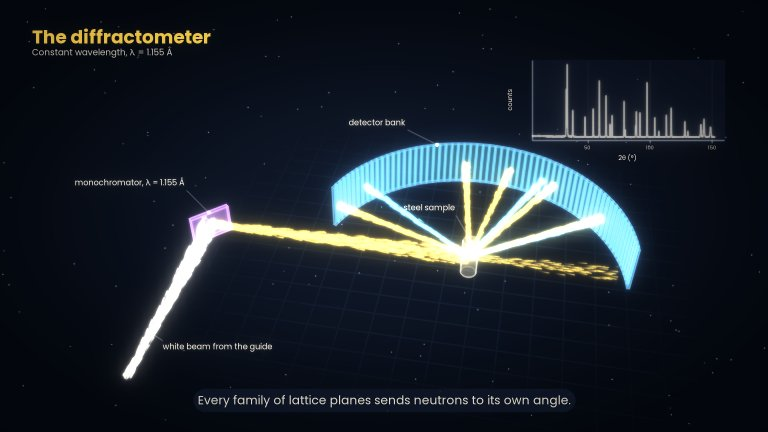

In [7]:
s1 = film.scenes[0]
s1.name = "Instrument"
cam = s1.camera
cam.set("target", (-35, 8, 0)).set("fov", 30).set("offset", (0, 40))
cam.key("azimuth", 0, -98).key("azimuth", 12, -78, "in_out")
cam.key("elevation", 0, 56).key("elevation", 12, 40, "in_out")
cam.key("distance", 0, 360).key("distance", 12, 320, "in_out")
film.add("title", text="The diffractometer", subtitle=f"Constant wavelength, λ = {LAMBDA} Å", start=0.2)
R = 62
film.add("grid3d", center=(-15, 10, -12), size=(200, 170), divisions=17, start=0.2)
film.add("beam", name="White beam", source=(-105, -80, 0), target=(-105, 0, 0), color="cream", rate=260,
         start=0.4)
film.add("box", name="Monochromator", center=(-105, 0, 0), size=(1.5, 16, 12), rotation=(0, 0, -45),
         edge_color="violet", fill_color="violet", fill_opacity=0.3, start=0.4)
film.add("beam", name="Monochromatic beam", source=(-105, 0, 0), target=(0, 0, 0), color="gold", start=1.2)
film.add("cylinder", name="Sample", radius=3, height=16, edge_color="cream", fill_opacity=0.25, start=0.6)
film.add("beam", name="Transmitted", source=(0, 0, 0), target=(R - 6, 0, 0), color="gold", rate=80,
         brightness=0.5, start=2.4)
for k, two_theta in enumerate(np.arange(5, 160.1, 2.5)):
    c, s = np.cos(np.radians(two_theta)), np.sin(np.radians(two_theta))
    film.add("box", name=f"Tube {k}", center=(R * c, R * s, 0), size=(1.0, 2.2, 20), rotation=(0, 0, two_theta),
             edge_color="blue", edge_width=1.2, fill_opacity=0.15, start=0.8 + 0.02 * k)
for k, (area, phase, hkl, x) in enumerate(strong[:8]):
    c, s = np.cos(np.radians(x)), np.sin(np.radians(x))
    film.add("beam", name=f"{phase} {hkl}", source=(0, 0, 0), target=((R - 1.5) * c, (R - 1.5) * s, 0),
             color=PHASES[phase]["color"], source_radius=0.8, target_radius=1.6, rate=60 + 160 * area / strong[0][0],
             brightness=0.5 + 0.7 * area / strong[0][0], start=3.0 + 0.3 * k)
film.add("label3d", point=(-105, -60, 0), text="white beam from the guide", offset=(30, 20), start=0.8)
film.add("label3d", point=(-105, 0, 6), text=f"monochromator, λ = {LAMBDA} Å", offset=(-60, -60), start=1.0)
film.add("label3d", point=(0, 0, 8), text="steel sample", offset=(-40, -70), start=1.4)
film.add("label3d", point=(R * np.cos(np.radians(110)), R * np.sin(np.radians(110)), 10), text="detector bank",
         offset=(-80, -40), start=2.0)
ax1 = film.add("axes", name="Counts", position=(1330, 150), size=(480, 200), x_range=(5, 160),
               y_range=(0, 1.05 * TOP), x_label="2θ (°)", y_label="counts", x_ticks=4, y_ticks=0, font_size=16,
               background_opacity=0.5, start=4.0)
counts = film.add("curve", axes=ax1, source="data", data="assets/pattern.csv", x_column="tth",
                  y_column="observed", color="cream", width=1.2, start=4.4)
counts.enter_duration = 6.0
film.add("caption", text="Every family of lattice planes sends neutrons to its own angle.", style="box",
         start=3.2, end=11.8)
show(s1, 9.0)

### Scene 2: two crystal structures

The unit cells of the two phases, built from spheres and boxes. One family of planes is drawn in each:
(110) in ferrite and (200) in austenite. Bragg's law gives the angle at which each family reflects.

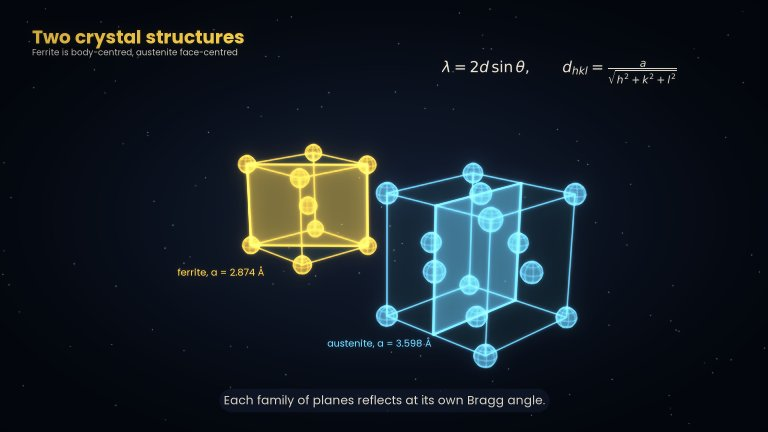

In [8]:
s2 = film.add_scene("Structures", 10.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Two crystal structures", subtitle="Ferrite is body-centred, austenite face-centred",
         start=0.2)
cam = s2.camera
cam.set("target", (0, 0, 0)).set("fov", 30).set("distance", 225).set("offset", (0, 30))
cam.key("azimuth", 0, -75).key("azimuth", 10, -40, "in_out")
cam.key("elevation", 0, 22).key("elevation", 10, 16, "in_out")
UNIT = 9.0                                              # scene units per ångström
CELLS = {"ferrite": (-34, [(0.5, 0.5, 0.5)]),
         "austenite": (34, [(0.5, 0.5, 0), (0.5, 0.5, 1), (0.5, 0, 0.5), (0.5, 1, 0.5), (0, 0.5, 0.5),
                            (1, 0.5, 0.5)])}
for phase, (cx, extra) in CELLS.items():
    a = q[P[f"a_{phase}"]] * UNIT
    color = PHASES[phase]["color"]
    film.add("box", name=f"{phase} cell", center=(cx, 0, 0), size=(a, a, a), edge_color=color, fill_opacity=0.03,
             start=0.5)
    corners = list(itertools.product((0, 1), repeat=3))
    for k, (fx, fy, fz) in enumerate(corners + extra):
        film.add("sphere", center=(cx + (fx - 0.5) * a, (fy - 0.5) * a, (fz - 0.5) * a), radius=2.6,
                 meridians=4, parallels=3, edge_color=color, fill_color=color, fill_opacity=0.5,
                 start=0.8 + 0.06 * k)
    film.add("label3d", point=(cx, 0, -a / 2), text=f"{phase}, a = {q[P[f'a_{phase}']]:.3f} Å", color=color,
             size=24, leader=False, dot=False, offset=(-110, 50), start=1.6)
a_f, a_a = q[P["a_ferrite"]] * UNIT, q[P["a_austenite"]] * UNIT
film.add("box", name="(110) planes", center=(-34, 0, 0), size=(a_f * np.sqrt(2), 0.3, a_f), rotation=(0, 0, 45),
         edge_color="ferrite", fill_color="ferrite", fill_opacity=0.25, start=3.5)
film.add("box", name="(200) planes", center=(34, 0, 0), size=(0.3, a_a, a_a), edge_color="austenite",
         fill_color="austenite", fill_opacity=0.25, start=4.0)
film.add("equation", tex=r"\lambda = 2d\,\sin\theta,\qquad d_{hkl} = \frac{a}{\sqrt{h^2+k^2+l^2}}",
         position=(1400, 180), size=38, start=5.0)
film.add("caption", text="Each family of planes reflects at its own Bragg angle.", style="box", start=5.5,
         end=9.8)
show(s2, 7.0)

### Scene 3: the pattern

The measured pattern with the strongest reflections labelled, and the tick marks of the two phases.

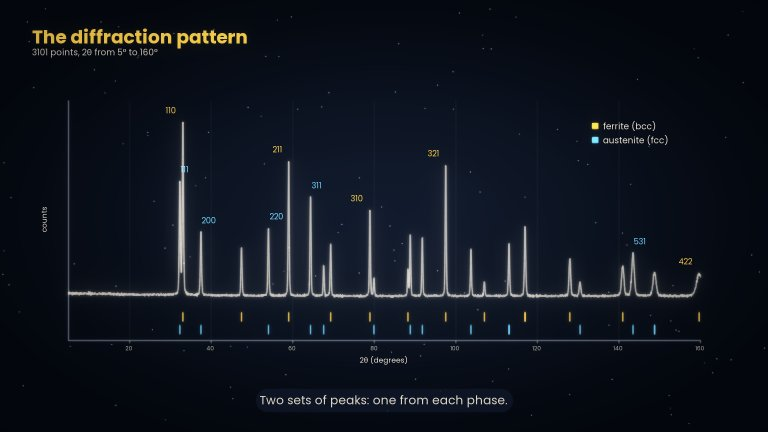

In [9]:
s3 = film.add_scene("Pattern", 9.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="The diffraction pattern", subtitle=f"{TTH.size} points, 2θ from 5° to 160°", start=0.2)
ax3 = film.add("axes", name="Pattern", position=(170, 250), size=(1580, 600), x_range=(5, 160),
               y_range=(-0.2 * TOP, 1.12 * TOP), x_label="2θ (degrees)", y_label="counts", x_ticks=8, y_ticks=0,
               start=0.4)
film.add("curve", name="Observed", axes=ax3, source="data", data="assets/pattern.csv", x_column="tth",
         y_column="observed", color="cream", width=1.4, start=0.8)
for row, phase in enumerate(PHASES):
    film.add("errorbars", name=f"{phase} reflections", axes=ax3, data=f"assets/ticks_{phase}.csv", x_column="x",
             y_column="y", y_error="err", points=False, cap=0, color=PHASES[phase]["color"], start=2.4 + 0.4 * row)
labelled = sorted(strong[:10], key=lambda r: r[3])
for k, (_, phase, hkl, x) in enumerate(labelled):
    height = observed[np.abs(TTH - x) < 0.3].max()
    film.add("marker", axes=ax3, x=x, y=height, size=0, guides="none", color=PHASES[phase]["color"], label=hkl,
             label_size=20, label_offset=(-16 if phase == "ferrite" else 4, -14), start=3.2 + 0.1 * k)
film.add("legend", entries="ferrite | ferrite (bcc)\naustenite | austenite (fcc)", position=(1480, 300), size=22,
         start=2.4)
film.add("caption", text="Two sets of peaks: one from each phase.", style="box", start=1.0, end=8.8)
show(s3, 6.0)

### Scene 4: the refinement

The calculated pattern (gold) walks through the refinement frames while the difference curve (teal) flattens
and the $R_{wp}$ counter falls. A line of text names the stage being refined.

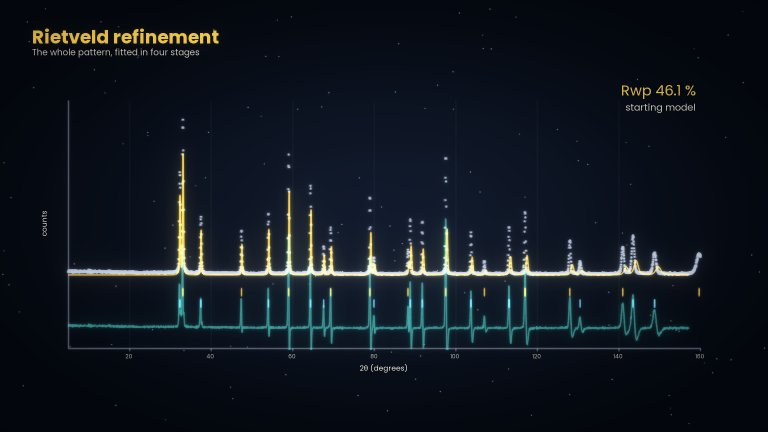

In [10]:
s4 = film.add_scene("Refinement", 14.0, transition="wipe_left", transition_duration=0.8)
film.add("title", text="Rietveld refinement", subtitle="The whole pattern, fitted in four stages", start=0.2)
ax4 = film.add("axes", name="Fit", position=(170, 250), size=(1580, 620), x_range=(5, 160),
               y_range=(-0.42 * TOP, 1.12 * TOP), x_label="2θ (degrees)", y_label="counts", x_ticks=8, y_ticks=0,
               start=0.3)
film.add("scatter", name="Observed", axes=ax4, data="assets/pattern.csv", x_column="tth", y_column="observed",
         color="gray", size=1.6, style="solid", start=0.5)
calc_curve = film.add("curve", name="Calculated", axes=ax4, source="data", data="assets/refinement/*.csv",
                      x_column="tth", y_column="calculated", color="gold", width=1.8, start=1.0)
diff_curve = film.add("curve", name="Difference", axes=ax4, source="data", data="assets/refinement/*.csv",
                      x_column="tth", y_column="difference", color="teal", width=1.2, start=1.0)
for phase in PHASES:
    film.add("errorbars", axes=ax4, data=f"assets/ticks_{phase}.csv", x_column="x", y_column="y", y_error="err",
             points=False, cap=0, color=PHASES[phase]["color"], start=1.0)
r_text = film.add("text", name="Rwp", text="Rwp {value:.1f} %", position=(1740, 200), size=36, color="gold",
                  align="right", start=1.0)
T0, T_STAGE = 2.0, 2.4                                  # when the refinement starts; seconds per stage
for k, value in enumerate(frame_rwp):
    t_k = T0 + T_STAGE * k / FRAMES_PER_STAGE
    calc_curve.key("step", t_k, k, "linear")
    diff_curve.key("step", t_k, k, "linear")
    r_text.key("value", t_k, value, "linear")
for k, (label, _) in enumerate(history):
    begin = 1.0 if k == 0 else T0 + T_STAGE * (k - 1)
    finish = T0 + T_STAGE * k if k < len(history) - 1 else 13.8
    film.add("text", text=(label if k == 0 else f"stage {k}: {label}"), position=(1740, 250), size=24,
             color="cream", align="right", start=begin, end=finish)
film.add("caption", text="Each stage frees more parameters; the difference curve flattens.", style="box",
         start=1.5, end=13.8)
show(s4, 1.5)

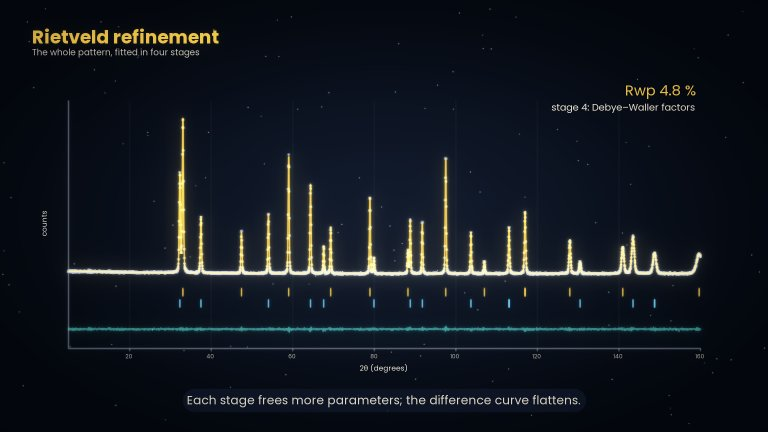

In [11]:
show(s4, 13.0)

### Scene 5: the result

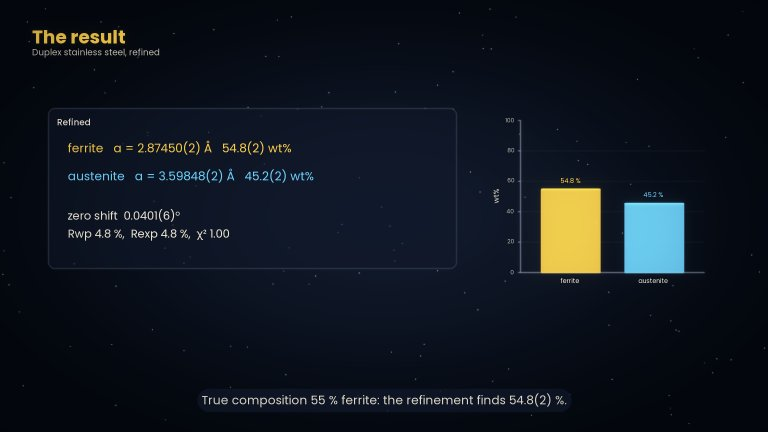

In [12]:
s5 = film.add_scene("Result", 8.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="The result", subtitle="Duplex stainless steel, refined", start=0.2)
film.add("panel", title="Refined", position=(120, 270), size=(1020, 400), start=0.4)
lines = []
for phase, w, dw in zip(PHASES, fractions, fraction_esd):
    i = P[f"a_{phase}"]
    lines.append(f"{phase}   a = {paren(q[i], esd[i])} Å   {paren(100 * w, 100 * dw)} wt%")
for k, line in enumerate(lines):
    film.add("text", text=line, position=(170, 350 + 70 * k), size=30, color=list(PHASES.values())[k]["color"],
             start=0.9 + 0.3 * k)
film.add("text", text=(f"zero shift  {paren(q[P['zero']], esd[P['zero']])}°\n"
                       f"Rwp {100 * r_wp:.1f} %,  Rexp {100 * r_exp:.1f} %,  χ² {(r_wp / r_exp) ** 2:.2f}"),
         position=(170, 520), size=28, line_spacing=1.6, start=1.6)
ax5 = film.add("axes", name="Fractions", position=(1300, 300), size=(460, 380), x_range=(0.4, 2.6),
               y_range=(0, 100), x_label="", y_label="wt%", x_ticks=0, y_ticks=5, start=0.6)
film.add("bars", axes=ax5, values=", ".join(f"{100 * w:.1f}" for w in fractions), labels="ferrite, austenite",
         colors="ferrite, austenite", value_labels=True, value_format="{value:.1f} %", start=1.2)
film.add("caption", text=f"True composition {100 * TRUE_W[0]:.0f} % ferrite: the refinement finds "
                         f"{paren(100 * fractions[0], 100 * fraction_esd[0])} %.", style="box", start=2.0,
         end=7.8)
show(s5, 5.0)

## Check, preview and render

no problems
5 scenes, 49.8 s: Instrument, Structures, Pattern, Refinement, Result



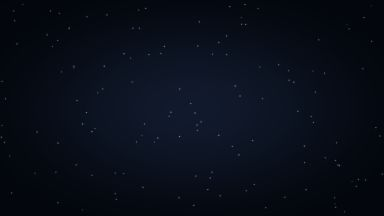

In [13]:
print(film.validate() or "no problems")
print(f"{len(film.scenes)} scenes, {film.duration:.1f} s:", ", ".join(sc.name for sc in film.scenes))
film.save()
film.preview(fps=3, scale=0.2)

In [14]:
video = film.render(FILM / "diffraction.mp4", scale=0.5)
print(f"wrote {video} ({video.stat().st_size / 1e6:.1f} MB)")

wrote films/diffraction/diffraction.mp4 (3.3 MB)
